# From GRPO to DAPO: Four Fixes for Long Reasoning RL

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/samaksh97/grpo-then-and-now/blob/main/notebook/dapo_four_fixes.ipynb)

GRPO is simple to state. Sample a group of responses, score them, normalize by the group's own mean and standard deviation, and push the policy toward whatever scored above average. Run it on long chain-of-thought math problems, however, and the DAPO paper (Decoupled Clip and Dynamic sAmpling Policy Optimization; Yu et al., NeurIPS 2025) reports four problems: entropy collapses, a growing share of groups has zero advantage, tokens of long responses are under-weighted, and truncated responses are scored as wrong. DAPO makes one change for each, and each change edits one piece of the GRPO objective.

**How to use this notebook** (about 45 minutes, CPU only, runs in about 3 seconds). Each of Sections 1–4 takes about 10 minutes. **Fast path:** read the setup below, then run each section's *Predict*, *Inspect* and *Explain* cells; the *Optional exploration* cells have no reference solution and can be skipped on a first pass. Prerequisites: the GRPO deck (`../slides/grpo_intro.html`) or `01_grpo_core.ipynb`. The companion deck is `../slides/dapo_intro.html`.

| Section | DAPO technique | Core cells | Time |
|---|---|---|---|
| 1 | Clip-Higher | clipped-objective plot; repeated updates on one rollout | 10 min |
| 2 | Dynamic Sampling | advantage table; P(informative) curve; batch simulation | 12 min |
| 3 | Token-level loss | weight table; length sweep; suppression race | 10 min |
| 4 | Overlong reward shaping | reward table; reward landscape; drift simulation | 10 min |

We'll take them one at a time, in the same rhythm every time: **predict, then inspect, then optimize, then explain**.

Both objectives are written out in full below, because every DAPO fix edits one term of the GRPO objective. Equation numbers refer to Yu et al. (2025).

### Setup and notation

Consider training a policy $\pi_\theta$ (a language model) on verifiable math problems. One training step goes like this:

1. Draw a question and answer pair $(q,a)$ from the dataset $\mathcal{D}$.
2. Freeze the current policy as the **rollout policy** $\pi_{\theta_{\mathrm{old}}}$ and sample a **group** of $G$ responses $\{o_i\}_{i=1}^{G}$ from it. Response $o_i$ has $|o_i|$ tokens, and $o_{i,t}$ is its $t$-th token.
3. Score each response with a rule, giving reward $R_i$.
4. Take several gradient steps on $\theta$ using those same responses. This is why the two policies drift apart and clipping starts to matter.

Two quantities show up in both objectives. The **importance ratio** measures how much more likely the current policy is to emit the token that actually got sampled, and the **advantage** says whether response $o_i$ beat its groupmates:

$$r_{i,t}(\theta)=\frac{\pi_\theta(o_{i,t}\mid q,o_{i,<t})}{\pi_{\theta_{\mathrm{old}}}(o_{i,t}\mid q,o_{i,<t})},
\qquad
\hat{A}_{i,t}=\frac{R_i-\operatorname{mean}(\{R_j\}_{j=1}^{G})}{\operatorname{std}(\{R_j\}_{j=1}^{G})}.$$

Two consequences that every fix relies on:

- **No value network.** GRPO drops PPO's learned critic entirely; the group's own reward statistics supply the baseline instead.
- **The advantage has no $t$ dependence.** Every token in response $o_i$ inherits the exact same $\hat{A}_{i,t}$, so one sequence-level reward gets spread evenly across all its tokens.

The reward itself is rule-based rather than a learned reward model, so there is no reward model to exploit (Eq. 7); a rule-based checker can still have loopholes:

$$R(\hat{y},y)=\begin{cases}\;\;\,1,&\mathtt{is\_equivalent}(\hat{y},y)\\-1,&\text{otherwise}\end{cases}$$

### GRPO's objective (Eq. 5)

$$\mathcal{J}_{\mathrm{GRPO}}(\theta)=\mathbb{E}_{(q,a)\sim\mathcal{D},\,\{o_i\}_{i=1}^{G}\sim\pi_{\theta_{\mathrm{old}}}}
\left[\underbrace{\frac{1}{G}\sum_{i=1}^{G}}_{\text{average over responses}}\;
\underbrace{\frac{1}{|o_i|}\sum_{t=1}^{|o_i|}}_{\substack{\text{average within}\\\text{each response}}}
\Big(\min\big(r_{i,t}\hat{A}_{i,t},\;\operatorname{clip}(r_{i,t},\,1-\varepsilon,\,1+\varepsilon)\,\hat{A}_{i,t}\big)-\beta D_{\mathrm{KL}}(\pi_\theta\|\pi_{\mathrm{ref}})\Big)\right]$$

The $\min$ against a clipped copy of the ratio comes straight from PPO. It caps how much any single update can be steered by one sample, keeping $\pi_\theta$ inside a trust region around $\pi_{\theta_{\mathrm{old}}}$. The $\beta D_{\mathrm{KL}}$ term anchors $\pi_\theta$ to a frozen reference model $\pi_{\mathrm{ref}}$.

Four properties of this setup cause the failures studied below:

1. The clipping range is **symmetric**: the same $\varepsilon$ above and below $1$.
2. Each response gets normalized by **its own length** $|o_i|$ before responses are averaged, so every response counts equally regardless of length.
3. **Every sampled group is kept**, including groups where all $G$ responses land the same reward, where $\operatorname{std}=0$ and the advantage carries no signal.
4. The **KL penalty** anchors the policy to $\pi_{\mathrm{ref}}$.

### DAPO's objective (Eq. 8)

$$\mathcal{J}_{\mathrm{DAPO}}(\theta)=\mathbb{E}_{(q,a)\sim\mathcal{D},\,\{o_i\}_{i=1}^{G}\sim\pi_{\theta_{\mathrm{old}}}}
\left[\underbrace{\frac{1}{\sum_{i=1}^{G}|o_i|}\sum_{i=1}^{G}\sum_{t=1}^{|o_i|}}_{\text{one average over all tokens}}
\min\Big(r_{i,t}\hat{A}_{i,t},\;\operatorname{clip}\big(r_{i,t},\,1-\varepsilon_{\mathrm{low}},\,1+\varepsilon_{\mathrm{high}}\big)\hat{A}_{i,t}\Big)\right]$$

$$\text{s.t.}\quad 0<\big|\{o_i \mid \mathtt{is\_equivalent}(a,o_i)\}\big|<G$$

The differences from Eq. 5:

- $\varepsilon$ splits into $\varepsilon_{\mathrm{low}}$ and $\varepsilon_{\mathrm{high}}$ (**Clip-Higher**), the "Decoupled Clip" half of the DAPO acronym.
- A new constraint demands each kept group have **at least one correct and at least one incorrect** response (**Dynamic Sampling**), the "Dynamic sAmpling" half of the acronym.
- The two nested averages collapse into **one flat average over all tokens in the group** (**Token-Level Policy Gradient Loss**).
- The $\beta D_{\mathrm{KL}}$ term is simply **gone**: a long chain-of-thought reasoning model is expected to wander far from where it started, so anchoring it to $\pi_{\mathrm{ref}}$ is unnecessary and works against the goal of training.

Separately, $R_i$ picks up an additive length penalty $R_{\mathrm{length}}$ (**Overlong Reward Shaping**, Eq. 13), which sits at $0$ for responses comfortably within budget and ramps down to $-1$ across a soft "cache" window near the limit. That's a change to the reward, not the objective's shape, which is why it never shows up as a new symbol above.

### The four fixes, at a glance

| # | Technique | Change to GRPO | Problem it solves |
|---|---|---|---|
| 1 | **Clip-Higher** | $\varepsilon\to(\varepsilon_{\mathrm{low}},\varepsilon_{\mathrm{high}})$, raising only the upper bound | Entropy collapse: the upper clip bounds rare exploration tokens far too tightly |
| 2 | **Dynamic Sampling** | Add the constraint $0<\lvert\{o_i\text{ correct}\}\rvert<G$; oversample to refill the batch | All correct or all wrong groups give zero advantage, hence zero gradient, shrinking batch gradient magnitude and raising noise |
| 3 | **Token-Level Loss** | $\frac{1}{G}\sum_i\frac{1}{\lvert o_i\rvert}\sum_t\;\to\;\frac{1}{\sum_i\lvert o_i\rvert}\sum_i\sum_t$ | Tokens in long responses get underweighted, so good long reasoning never gets learned and long-form gibberish never gets penalized |
| 4 | **Overlong Reward Shaping** | Add $R_{\mathrm{length}}$ to $R_i$ | Truncation noise: sound reasoning gets penalized purely for being cut off |

Reported hyperparameters: $\varepsilon_{\mathrm{low}}=0.2$, $\varepsilon_{\mathrm{high}}=0.28$, $G=16$ responses per prompt, prompt batch size $512$, generation budget $20{,}480$ tokens ($16{,}384$ expected plus $4{,}096$ soft punishment cache).

### The paper's ablation (Table 1)

Each fix adds accuracy on AIME 2024 (avg@32, Qwen2.5-32B base):

| Configuration | AIME24 |
|---|---:|
| Naive GRPO | 30 |
| + Overlong Filtering | 36 |
| + Clip-Higher | 38 |
| + Soft Overlong Punishment | 41 |
| + Token-level Loss | 42 |
| + Dynamic Sampling (**DAPO**) | **50** |
| *DeepSeek-R1-Zero-Qwen-32B (reference)* | *47* |

Naive GRPO lands at 30. All four techniques together reach 50, exceeding the DeepSeek-R1-Zero-Qwen-32B reference (47) with half its training steps. Note that *Overlong Filtering* (masking the loss on truncated samples) is the diagnostic that first proved truncation noise was a real problem; *Soft Overlong Punishment* is the actual fix that Section 4 covers. Token-level loss buys the least raw accuracy of the four, but the paper credits it with meaningfully healthier training dynamics and controlled response length growth.

Sections 1 through 4 take these one at a time.

## 1. Clip-Higher: Give Rare Successful Tokens Room to Grow *(about 10 min)*

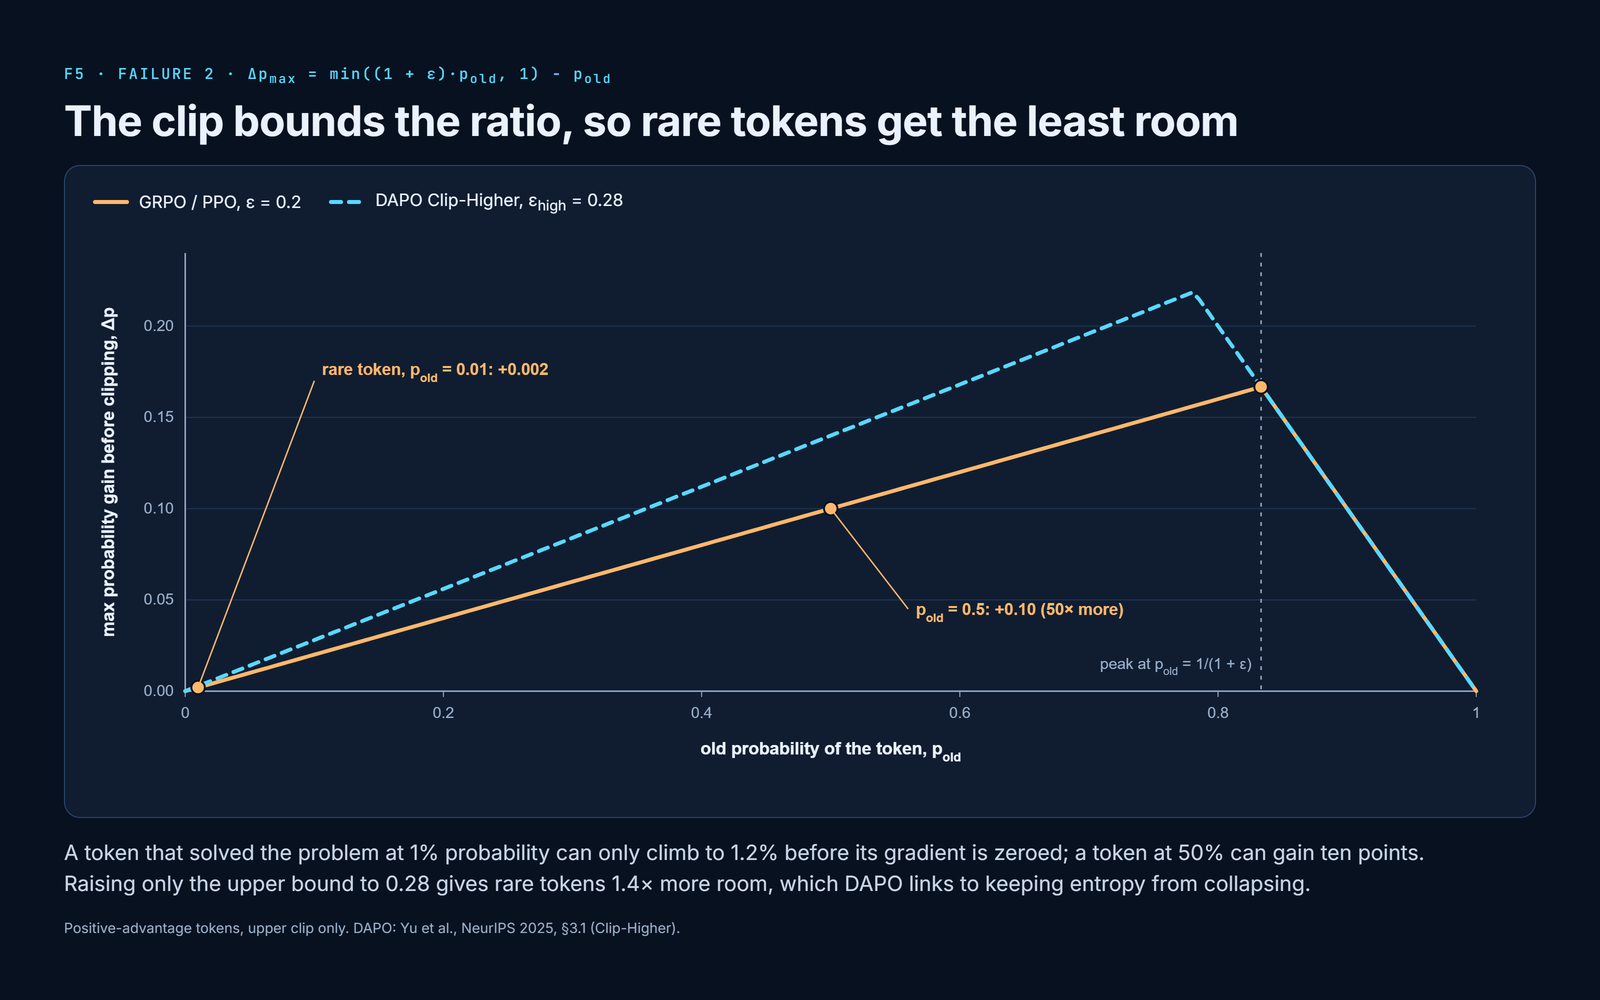

**What you'll observe:** with the symmetric clip a rare winning token stops at 1.2 times its old probability; raising only the upper bound lets it reach 1.5 times.

**What changes.** Exactly one thing changes in this section:

$$\operatorname{clip}\big(r_{i,t},\,1-\varepsilon,\,1+\varepsilon\big)
\;\longrightarrow\;
\operatorname{clip}\big(r_{i,t},\,1-\varepsilon_{\mathrm{low}},\,1+\varepsilon_{\mathrm{high}}\big),
\qquad \varepsilon_{\mathrm{high}}>\varepsilon_{\mathrm{low}}.$$

The advantage, the averaging, and the rollout procedure all stay exactly as they were. Notice that **only the upper bound moves**. The paper deliberately keeps $\varepsilon_{\mathrm{low}}$ pinned at $0.2$, because raising the lower bound would let a single update shove token probabilities toward $0$ and collapse the sampling space. DAPO uses $\varepsilon_{\mathrm{high}}=0.28$; we'll use $0.5$ below so the gap actually shows up on a plot.

### Question to consider

A rare reasoning strategy pays off. Why does ordinary GRPO struggle to make it more likely next time?

Picture a geometry problem where the model has to choose its opening move:

| Opening token | Old probability | Interpretation |
|---|---:|---|
| `Let` | 0.80 | Familiar algebraic approach |
| `Draw` | 0.02 | Rare diagram-based approach |
| Other tokens | 0.18 | Other approaches |

A sampled response that opens with `Draw` solves the problem, earning positive advantage $\hat{A}_{i,t}>0$, and the update tries to make `Draw` more likely. Its importance ratio at that position is

$$r_{i,t} = \frac{\pi_\theta(\text{Draw}\mid q)}{\pi_{\theta_{\mathrm{old}}}(\text{Draw}\mid q)}.$$

The asymmetry that motivates the fix: clipping bounds the **ratio**, not the probability. A ceiling of $1+\varepsilon$ on the ratio only ever permits an absolute probability increase of $p_{\mathrm{old}}\,\varepsilon$, and that number shrinks as the token gets rarer. Rare exploration tokens get handed the least room to grow, while a high-probability token's ceiling can sail past $1$ and never bind at all.

> The paper makes this concrete with $\varepsilon=0.2$ and two tokens sitting at $\pi_{\theta_{\mathrm{old}}}=0.01$ and $0.9$: their ceilings work out to $0.012$ and $1.08$. The exploitation token is effectively unconstrained (nothing stops it from reaching $0.999$), while the exploration token can gain at most $0.002$. DAPO reports empirically that the mean probability of up-clipped tokens sits below $0.2$, which confirms it really is exploration tokens hitting the upper clip.


### Predict

The old probability of `Draw` is 0.02. Before running the next cell, guess its probability once the ratio first reaches:

- GRPO's symmetric upper bound, $1 + 0.2 = 1.2$
- DAPO's higher upper bound, $1 + 0.5 = 1.5$


In [1]:
# Setup: make grpo_lab importable
import sys, pathlib, subprocess
ROOT = next((p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p / "grpo_lab").exists()), None)
if ROOT is None:   # e.g. opened in Colab: fetch the repository (code, data and figures) first
    subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/samaksh97/grpo-then-and-now"], check=True)
    ROOT = pathlib.Path("grpo-then-and-now").resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
from grpo_lab import plots

In [2]:
# Clip-Higher arithmetic: the ratio cap 1 + eps limits a token with old probability p_old to
# p_old * (1 + eps). Compare GRPO's eps = 0.2 with the wide toy eps_high = 0.5 used in this section.
p_old = 0.02
eps_symmetric = 0.20
eps_high = 0.50

p_at_symmetric_ceiling = p_old * (1 + eps_symmetric)
p_at_clip_higher_ceiling = p_old * (1 + eps_high)

grpo_room = p_at_symmetric_ceiling - p_old
dapo_room = p_at_clip_higher_ceiling - p_old

print(f"Old probability:          {p_old:.3f}")
print(f"GRPO clipping threshold:  {p_at_symmetric_ceiling:.3f}")
print(f"DAPO clipping threshold:  {p_at_clip_higher_ceiling:.3f}")
print(f"\nRoom supplied by Clip-Higher: {dapo_room / grpo_room:.1f}x as much")


Old probability:          0.020
GRPO clipping threshold:  0.024
DAPO clipping threshold:  0.030

Room supplied by Clip-Higher: 2.5x as much


For this sampled token context pair, GRPO's positive-advantage surrogate goes flat once the ratio hits 1.2. DAPO keeps rewarding the probability increase all the way out to a ratio of 1.5.

That threshold is not a permanent ceiling on the token's probability; other samples and later rollout batches can still move it. It marks the point where this particular sample stops supplying a positive gradient.


### Inspect the clipped objective

Pull a single token out of the sum in the DAPO objective, with positive advantage $\hat{A}>0$, and the per-token surrogate is

$$L(r,\hat{A})=\min\Big(r\hat{A},\;\operatorname{clip}\big(r,\,1-\varepsilon_{\mathrm{low}},\,1+\varepsilon_{\mathrm{high}}\big)\hat{A}\Big).$$

Set $\varepsilon_{\mathrm{high}}=\varepsilon_{\mathrm{low}}=0.2$ and you're back to GRPO; raise $\varepsilon_{\mathrm{high}}$ and you get Clip-Higher. The next plot shows exactly where each objective flattens out, and a flat objective means zero gradient, so the update stops there.


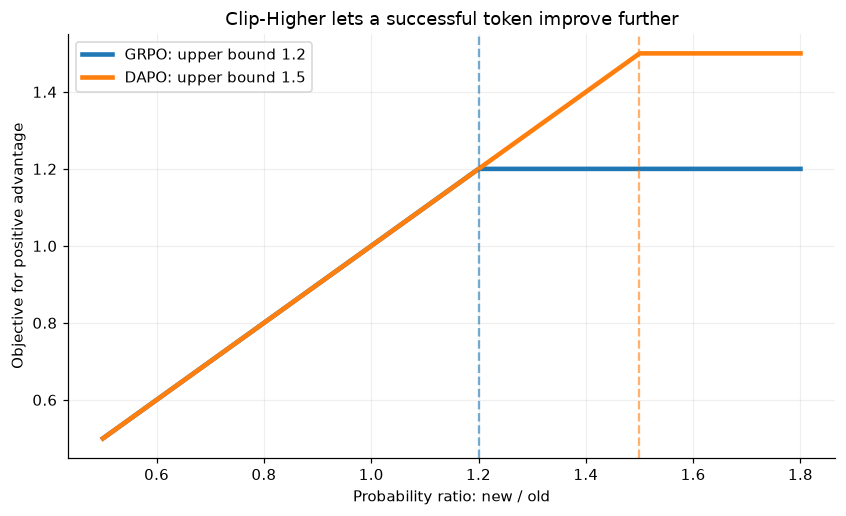

In [3]:
# Per-token clipped objective for a positive advantage under GRPO's and DAPO's bounds.
# Where a curve is flat, that token's gradient is zero.
ratios = np.linspace(0.5, 1.8, 400)
advantage = 1.0
eps_low = 0.2

def clipped_surrogate(ratios, advantage, eps_low, eps_high):
    """min(r A, clip(r, 1 - eps_low, 1 + eps_high) A): the per-token term of DAPO's objective (Eq. 8)."""
    return np.minimum(ratios * advantage, np.clip(ratios, 1 - eps_low, 1 + eps_high) * advantage)

grpo_objective = clipped_surrogate(ratios, advantage, eps_low=0.2, eps_high=0.2)
dapo_objective = clipped_surrogate(ratios, advantage, eps_low=0.2, eps_high=0.5)
plots.dapo_surrogates(ratios, grpo_objective, dapo_objective)

### Optimize the same rollout more than once

Clipping only starts to matter once the current policy drifts away from the policy that generated the rollout. So we freeze the old probability and run multiple optimization steps on the same positive advantage sample.

This one-action Bernoulli model is a local model of one token, not a full language model. It isolates the clipping mechanism cleanly instead of burying it inside a neural network.


In [4]:
# A one-action toy: the token's probability is sigmoid(z). We take repeated gradient steps on a single
# positive-advantage sample, measuring its ratio against the frozen old probability p_old.
from grpo_lab.objectives import sigmoid, logit

def optimize_positive_token(p_old, eps_high, learning_rate=0.01, epochs=250):
    """Optimize one positive-advantage action against a frozen rollout policy."""
    z = logit(p_old)
    history = []
    for epoch in range(epochs):
        p_new = sigmoid(z)
        ratio = p_new / p_old
        # Positive advantage: the clipped term stops contributing once the ratio reaches 1 + eps_high.
        gradient_active = ratio < 1 + eps_high
        # For A=1, d(ratio)/dz = ratio * (1 - p_new).
        gradient = ratio * (1 - p_new) if gradient_active else 0.0
        history.append({"epoch": epoch, "probability": p_new, "ratio": ratio, "gradient_active": gradient_active})
        z += learning_rate * gradient
    return history

grpo_history = optimize_positive_token(p_old=0.02, eps_high=0.20)
dapo_history = optimize_positive_token(p_old=0.02, eps_high=0.50)

print(f"GRPO final probability: {grpo_history[-1]['probability']:.4f}")
print(f"DAPO final probability: {dapo_history[-1]['probability']:.4f}")

GRPO final probability: 0.0241
DAPO final probability: 0.0303


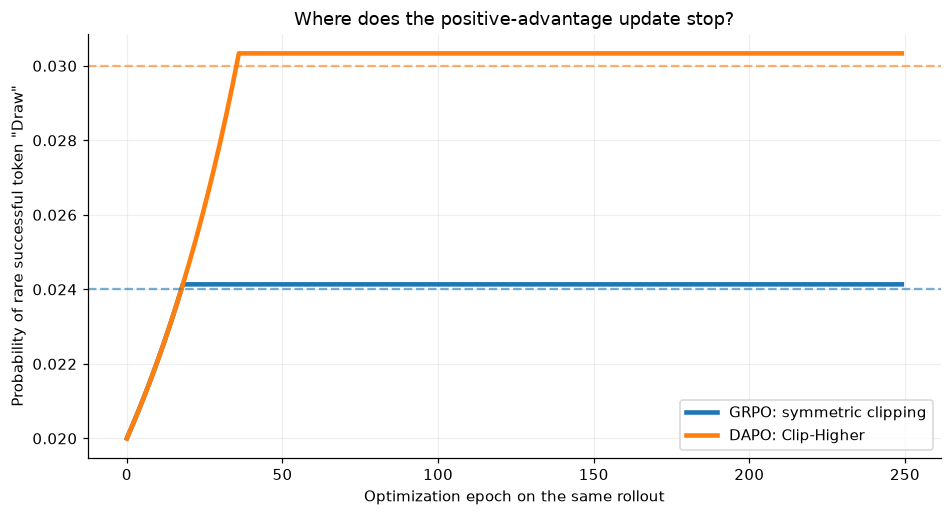

In [5]:
# Probability of the rare token over epochs; dashed lines mark each method's threshold p_old * (1 + eps).
plots.rare_token_probability(grpo_history, dapo_history, p_old)

### Explain

> GRPO's upper clipping bound can stop a rare successful token after only a small absolute probability increase. DAPO raises that bound, letting exploration tokens become meaningfully more likely before their positive update gets clipped away.

Clip-Higher doesn't add an entropy bonus, doesn't guarantee entropy always rises, and doesn't remove clipping. It gives positively advantaged tokens more room to grow. DAPO reports that the tokens hitting the upper clip tend to be low-probability exploration tokens, so widening the upper range is a targeted way to preserve diversity.


### Optional exploration (no reference solution)

Try old probabilities `[0.50, 0.10, 0.02, 0.001]` and upper clipping values `[0.20, 0.30, 0.50, 0.80]`. Plot the allowed absolute increase $p_{\mathrm{old}}\epsilon_{\mathrm{high}}$.

Then think through:

1. Which tokens get the smallest absolute increase?
2. Why do repeated rollout and update cycles matter here?
3. Why might an extremely large upper bound make training less conservative than you'd want?


In [6]:
old_probabilities = np.array([0.50, 0.10, 0.02, 0.001])
upper_clip_values = np.array([0.20, 0.30, 0.50, 0.80])

# TODO: Create one curve per old probability.
# Hint: allowed absolute increase = p_old * eps_high


---

## 2. Dynamic Sampling: Spend Compute Only on Informative Groups *(about 10 min)*

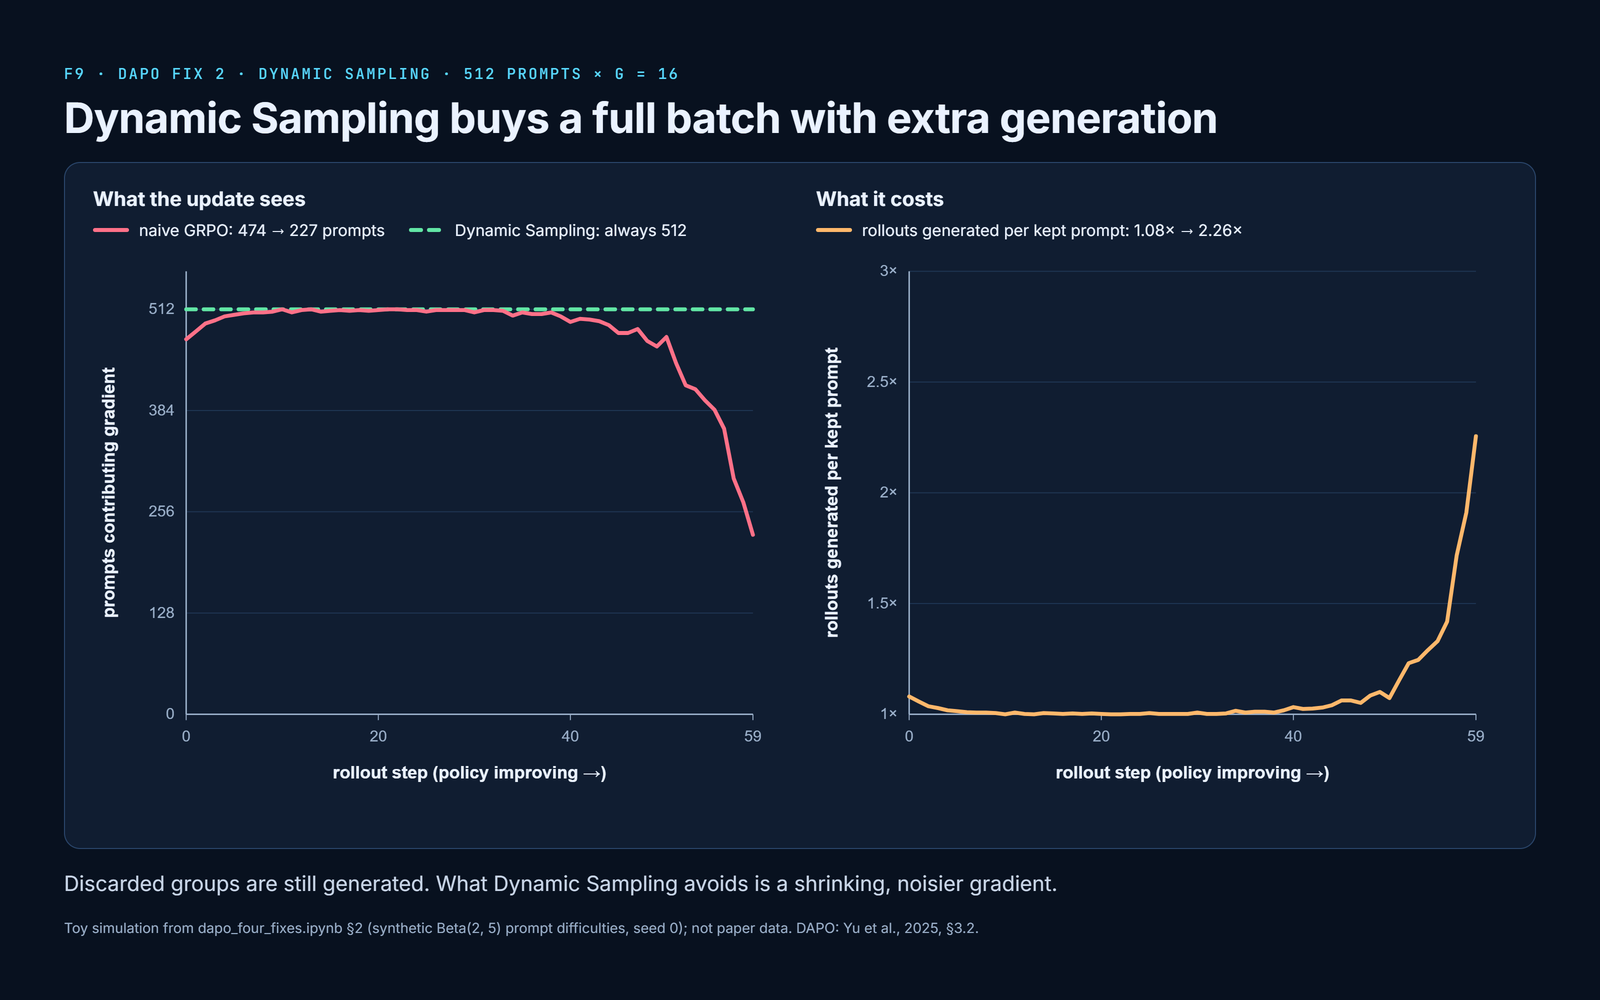

**What you'll observe:** as the policy improves, fewer groups disagree; Dynamic Sampling keeps the batch full by generating more responses.

**What changes.** This fix doesn't add a single new symbol to the loss. It adds a *constraint on which groups are even allowed into the batch*:

$$\text{s.t.}\quad 0<\big|\{o_i \mid \mathtt{is\_equivalent}(a,o_i)\}\big|<G$$

In plain words: **keep a prompt only if its group has at least one correct and at least one incorrect response.** Groups that agree unanimously (all right or all wrong) are dropped, and fresh prompts get sampled to take their place.

### Question to consider

Your model already answers a prompt correctly in all $G$ attempts. How much does that prompt contribute to this training step?

Nothing: this follows directly from the advantage formula. Recall

$$\hat{A}_{i,t}=\frac{R_i-\operatorname{mean}(\{R_j\})}{\operatorname{std}(\{R_j\})}.$$

With the rule-based reward $R_i\in\{+1,-1\}$, if all $G$ responses come back correct, every $R_i=+1$, so $\operatorname{mean}=+1$ and every numerator $R_i-\operatorname{mean}$ is $0$. The advantage vanishes for every token of every response in the group.

Because the advantage multiplies the entire surrogate, $\hat{A}_{i,t}=0$ means **zero loss and zero gradient** out of that prompt. The model generated $G$ full chains of thought and learned nothing from any of them.

The exact same thing happens when all $G$ responses are wrong: every $R_i=-1$, mean $=-1$, numerator $=0$. Unanimity in *either* direction is the problem, which is exactly why the constraint cuts both ways.

> **A quick note on $\operatorname{std}=0$.** When rewards are unanimous the denominator is also zero, so the ratio is formally $0/0$. Real implementations divide by $\operatorname{std}+\epsilon$ with a tiny $\epsilon$ (say $10^{-6}$), which makes the advantage come out to exactly $0$, matching the paper's own description that "the resulting advantage for this group is zero." The code below does the same thing, so you can watch it happen instead of taking it on faith.

### Why this gets *worse* as the model improves

A group is unanimously correct precisely when the model has already mastered that prompt. So **the better the policy gets, the fewer of its prompts contribute any gradient.** The paper documents exactly this: the share of prompts with accuracy $1$ climbs steadily during training (Figure 3(b)), so the effective batch size shrinks step after step even while the nominal batch size sits fixed at 512 prompts.

Two consequences the paper names directly:

1. **Shrinking gradient magnitude.** The loss is averaged over a fixed denominator, but fewer and fewer prompts contribute a nonzero numerator.
2. **Rising gradient noise.** The batch gradient is effectively estimated from a smaller sample, so its variance grows. Training gets less stable exactly as the model gets stronger.

Success degrades the training signal. That's the failure mode Dynamic Sampling exists to repair.


### Predict

Take $G=8$ responses per prompt and the $\pm 1$ reward. Before running the next cell, guess which of these groups produce a **nonzero** gradient:

| Group | Correct responses |
|---|---:|
| impossible | 0 / 8 |
| hard | 1 / 8 |
| balanced | 4 / 8 |
| easy | 7 / 8 |
| mastered | 8 / 8 |

Then guess something less obvious: **which group hands the single largest advantage magnitude to any one response?** The balanced group, or one of the lopsided ones?


In [7]:
# Advantages for groups of 8 with 0, 1, 4, 7 or 8 correct answers (+1/-1 rewards): which give a gradient?
import numpy as np

REWARD_CORRECT, REWARD_WRONG = 1.0, -1.0

def group_advantages(rewards, eps=1e-6):
    """Group-normalized advantage, Eq. 9.

    The eps in the denominator is what real implementations use; it makes a
    unanimous group evaluate to exactly zero instead of 0/0.
    """
    rewards = np.asarray(rewards, dtype=float)
    return (rewards - rewards.mean()) / (rewards.std() + eps)

def make_group(n_correct, group_size=8):
    return np.array([REWARD_CORRECT] * n_correct
                    + [REWARD_WRONG] * (group_size - n_correct))

G = 8
labels = {0: "impossible", 1: "hard", 4: "balanced", 7: "easy", 8: "mastered"}

print(f"{'group':12s} {'correct':>8s} {'mean R':>8s} {'std R':>7s} {'max |A|':>8s}   gradient")
print("-" * 62)
for n_correct, label in labels.items():
    rewards = make_group(n_correct, G)
    A = group_advantages(rewards)
    flows = "flows" if not np.allclose(A, 0.0) else "ZERO -- wasted rollouts"
    print(f"{label:12s} {n_correct:5d}/{G} {rewards.mean():+8.2f} {rewards.std():7.2f} "
          f"{np.abs(A).max():8.3f}   {flows}")


group         correct   mean R   std R  max |A|   gradient
--------------------------------------------------------------
impossible       0/8    -1.00    0.00    0.000   ZERO -- wasted rollouts
hard             1/8    -0.75    0.66    2.646   flows
balanced         4/8    +0.00    1.00    1.000   flows
easy             7/8    +0.75    0.66    2.646   flows
mastered         8/8    +1.00    0.00    0.000   ZERO -- wasted rollouts


The answer to the second question: the **lopsided** groups, not the balanced one. Both 1/8 and 7/8 hand one single response an advantage of about $2.65$, versus just $1.0$ for every response in the balanced group, and the two tie exactly, because the formula is symmetric under swapping "correct" for "incorrect." A lone success among seven failures (or a lone failure among seven successes) is the sharpest signal in the whole batch: it isolates exactly what made that one response different from the rest.

So Dynamic Sampling is **not** "drop the hard prompts." A 1 of 8 group is the single most valuable group there is. The only thing that gets discarded is *unanimity*.

### Inspect: how often is a group actually informative?

Whether a group ends up unanimous depends entirely on how good the model already is at that prompt. Model each of the $G$ responses as an independent success with probability $p$ (the model's per-response accuracy on that prompt). Then

$$P(\text{unanimously correct}) = p^{G},\qquad P(\text{unanimously wrong}) = (1-p)^{G},$$

$$P(\text{informative}) = 1 - p^{G} - (1-p)^{G}.$$

> **A modeling caveat.** Independence here is an approximation. Real responses to the same prompt are *correlated*: they come from one policy that tends to make the same mistakes over and over, so genuine groups end up unanimous **more** often than this formula predicts. Treat the curves below as an optimistic upper bound on how much signal actually survives.

The plot shows why difficulty matters this much, and what group size actually buys you.


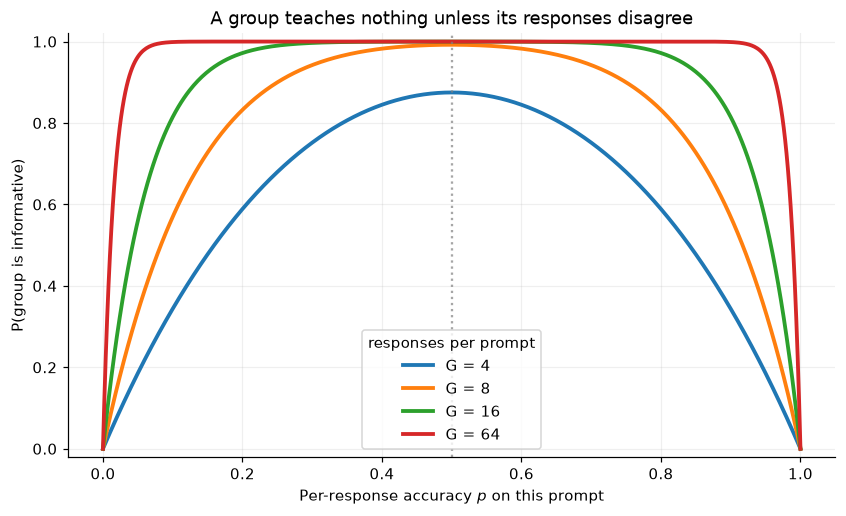

P(informative) as the model masters a prompt:
     p       G=4       G=8      G=16      G=64
  0.50     0.875     0.992     1.000     1.000
  0.80     0.589     0.832     0.972     1.000
  0.90     0.344     0.570     0.815     0.999
  0.95     0.185     0.337     0.560     0.962
  0.99     0.039     0.077     0.149     0.474


In [8]:
# P(informative) = 1 - p^G - (1-p)^G for G independent responses with accuracy p.
def prob_informative(p, group_size):
    """P(group has >=1 correct AND >=1 incorrect), for iid Bernoulli(p) responses."""
    p = np.asarray(p, dtype=float)
    return 1.0 - p ** group_size - (1.0 - p) ** group_size

plots.informative_share(np.linspace(0.0, 1.0, 501), prob_informative, group_sizes=(4, 8, 16, 64))

print("P(informative) as the model masters a prompt:")
print(f"{'p':>6s}" + "".join(f"{f'G={g}':>10s}" for g in (4, 8, 16, 64)))
for p in (0.5, 0.8, 0.9, 0.95, 0.99):
    row = "".join(f"{prob_informative(p, g):10.3f}" for g in (4, 8, 16, 64))
    print(f"{p:6.2f}{row}")

### Optimize: the effective batch over a training run

A single prompt says little about training dynamics, so we simulate the paper's setup, **512 prompts per batch, $G=16$ responses each**, over a run where the policy steadily improves. Prompt difficulty varies, so at any moment the batch holds a mix of mastered, learnable, and still impossible prompts.

We compare two regimes:

- **Naive GRPO**: generate $512\times 16$ responses, keep every single group. Unanimous groups contribute zero. The *nominal* batch stays pinned at 512 while the *effective* batch quietly shrinks.
- **Dynamic Sampling**: keep generating and discarding unanimous groups until you've collected 512 *informative* prompts. The effective batch is 512 by construction; what varies is the generation cost.

Watch three things: how many prompts actually contribute, how noisy the resulting gradient estimate gets, and what the extra generation ends up costing.


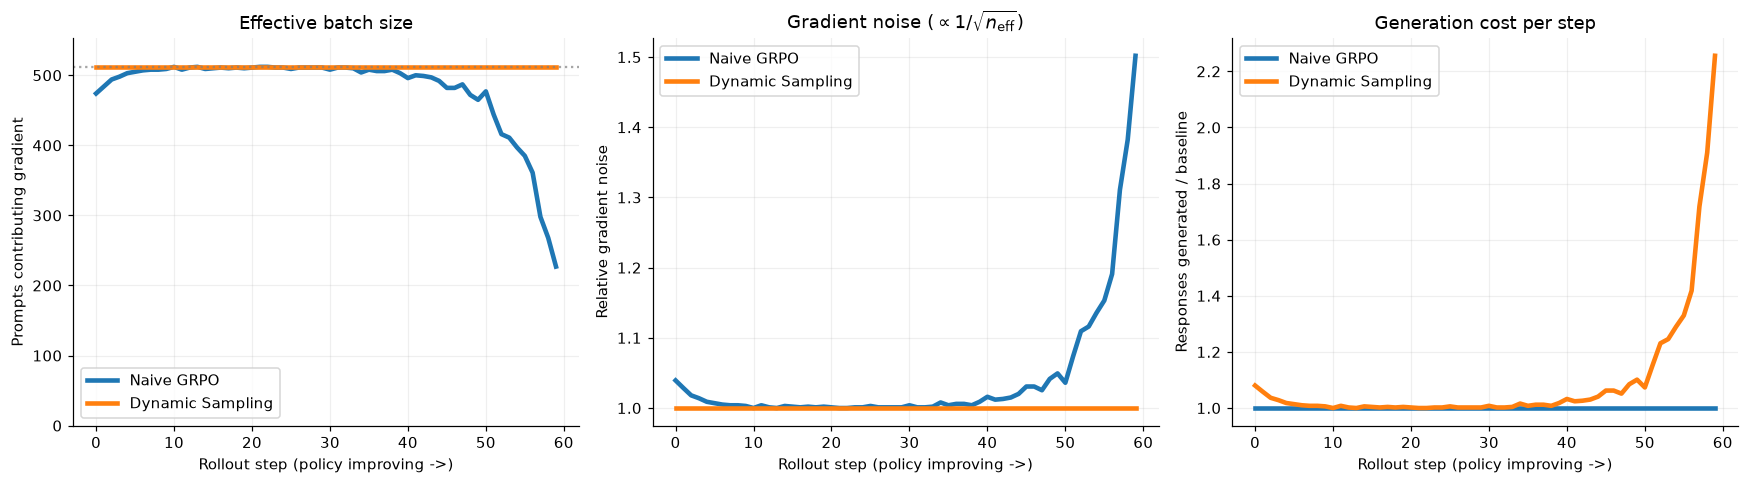

Start of run: 474/512 prompts informative (93%), dynamic-sampling cost 1.08x
End of run:   227/512 prompts informative (44%), dynamic-sampling cost 2.26x

Naive GRPO's gradient noise grew 1.45x over the run,
while its nominal batch size never changed.


In [9]:
# Simulate a training run (512 prompts x 16 responses per step, synthetic prompt difficulties) and compare
# naive GRPO's effective batch with the extra generation Dynamic Sampling needs to keep its batch full.
from grpo_lab.dapo import effective_batch_run, prompt_accuracies, is_informative

PROMPT_BATCH = 512   # prompts per rollout step (paper)
GROUP_SIZE = 16      # responses per prompt (paper)
run = effective_batch_run(PROMPT_BATCH, GROUP_SIZE, n_steps=60, seed=0)
plots.effective_batch(run, PROMPT_BATCH)

naive_effective, cost_multiplier, naive_noise = run["naive_effective"], run["cost_multiplier"], run["naive_noise"]
print(f"Start of run: {naive_effective[0]:3d}/{PROMPT_BATCH} prompts informative "
      f"({100 * naive_effective[0] / PROMPT_BATCH:.0f}%), "
      f"dynamic-sampling cost {cost_multiplier[0]:.2f}x")
print(f"End of run:   {naive_effective[-1]:3d}/{PROMPT_BATCH} prompts informative "
      f"({100 * naive_effective[-1] / PROMPT_BATCH:.0f}%), "
      f"dynamic-sampling cost {cost_multiplier[-1]:.2f}x")
print(f"\nNaive GRPO's gradient noise grew {naive_noise[-1] / naive_noise[0]:.2f}x over the run,")
print("while its nominal batch size never changed.")

### Interactive: find the setting where GRPO wastes the most compute

Use the sliders to explore the trade-off:

1. Hold accuracy at $0.95$ and raise the group size. Does a bigger group actually rescue the signal, or does it just cost more?
2. Find a setting where naive GRPO throws away **more than 90%** of its generated responses. Is that regime realistic late in training?

*(If `ipywidgets` isn't available, the cell prints a static sweep with the same numbers.)*


In [10]:
# Interactive: effective batch and generation cost at one (accuracy, group size) point.
# Falls back to a printed table when ipywidgets is unavailable.
plots.interactive_sampling(prob_informative, PROMPT_BATCH)

interactive(children=(FloatSlider(value=0.95, continuous_update=False, description='accuracy p', max=1.0, step…

### Explain

> A group whose responses all agree has zero standard deviation, hence zero advantage, hence zero gradient, so those rollouts contribute nothing to the update. Because agreement gets more likely as the policy improves, naive GRPO's effective batch shrinks and its gradient noise grows precisely as training progresses. Dynamic Sampling restores a constant effective batch by oversampling and throwing out unanimous groups.

What Dynamic Sampling **is not**:

- It does **not** create new signal. It reallocates a fixed generation budget toward prompts that already have signal.
- It is **not** a curriculum that drops hard prompts. A 1 of 16 group gets kept, and is the most informative group in the whole batch. Only *unanimous* groups get dropped.
- It is **not** free. The filtering costs extra generation, and the multiplier climbs the better the model gets.
- It does **not** recover the compute already spent on unanimous groups; that cost is paid with or without filtering. What changes is that every update averages over a full batch of informative prompts instead of a batch diluted by zero-advantage groups.

Why the cost is tolerable in practice, per the paper: in a synchronized, non-pipelined RL system the wall-clock time of a rollout step is dominated by its **longest** response, not by the *number* of responses. Sampling extra groups mostly fills otherwise idle capacity. The paper reports that dynamic sampling reaches the same performance **faster** overall, since convergence needs fewer training steps (Figure 6).

In the ablation, this is the single largest jump of all four techniques: **42 to 50** on AIME 2024.

### A caveat

The constraint quietly changes *which prompts train the model*. Every kept prompt has mixed outcomes, so the training distribution gets pulled toward whatever sits right at the edge of the model's ability, and away from both mastered and hopeless prompts. That is usually desirable (it is close to a self-adjusting curriculum), but it is a real distributional shift, not a neutral efficiency trick, and the paper does not analyze it. Two consequences:

- Prompts the model has already mastered stop being trained on entirely. Nothing in the objective protects against forgetting them later.
- A prompt that's genuinely impossible (a broken label, an unparseable answer) is always unanimously wrong, so it is silently discarded, which incidentally removes broken data from training.


### Optional exploration (no reference solution)

Implement the sampling loop itself, rather than the closed-form estimate. Write `fill_batch(...)` that keeps drawing prompts until it holds `target` informative groups, and returns both the kept groups and the *total* number of responses generated along the way.

Then measure:

1. **The real cost multiplier.** Compare your measured `responses_generated / (target * G)` against the closed-form prediction $1/P(\text{informative})$. Do they agree? This checks where the $1/P$ comes from.
2. **Correlated responses.** Swap the independent Bernoulli draws for a correlated model, so responses within a group agree more often than pure chance would suggest. How much does unanimity increase, and how much more expensive does Dynamic Sampling get as a result?
3. **The unlucky tail.** Plot the *distribution* of responses generated per step, not just the mean. If a batch occasionally needs 5x the budget to fill, what does that do to a synchronized system where every worker sits waiting for the slowest?

Then think through:

- At $p=0.99$ and $G=16$, $P(\text{informative})\approx 15\%$. Would you raise $G$, lower the batch size, or change the dataset instead?
- Dynamic Sampling filters on *outcome* unanimity. What if two responses land on the same right answer through completely different reasoning? The constraint has no signal there at all. Is that a real limitation?


In [11]:
def fill_batch(target, group_size, skill, rng, max_draws=100_000):
    """Keep sampling prompts until `target` informative groups are collected.

    Returns (n_correct_per_kept_group, total_responses_generated).
    """
    kept, responses_generated = [], 0
    # TODO: loop until len(kept) == target
    #   1. draw one prompt's accuracy with prompt_accuracies(skill, 1, rng)
    #   2. roll its G responses:  n_correct = rng.binomial(group_size, p)
    #   3. responses_generated += group_size   <- count every response, kept or not
    #   4. keep the group only if 0 < n_correct < group_size
    return np.array(kept), responses_generated

# Once implemented, check the measured multiplier against the closed form:
#
# kept, generated = fill_batch(target=256, group_size=16, skill=0.6,
#                              rng=np.random.default_rng(1))
# print(f"measured {generated / (256 * 16):.2f}x")


---

## 3. Token-Level Policy Gradient Loss: Give Every Token an Equal Vote *(about 10 min)*

![Per-token weight against response length on log axes for a group of 8 in which seven responses have 200 tokens: GRPO's sample-level weight falls as one over the length, so a 20-token answer weighs 10 times more per token, while DAPO's token-level weight and Dr. GRPO's constant stay nearly flat.](attachment:F06_per_token_weight_vs_length.png)

**What you'll observe:** under a sample-level average a bad token buried in a long response is suppressed slowest; a token-level average treats every token alike.

**What changes.** Exactly one thing changes in this section: how the per-token surrogate values (the same $\min(\cdot)$ term from Eq. 5, held fixed) get summed into one scalar.

$$\underbrace{\frac{1}{G}\sum_{i=1}^{G}\frac{1}{|o_i|}\sum_{t=1}^{|o_i|}}_{\text{GRPO: sample-level}}(\cdot)\;\longrightarrow\;\underbrace{\frac{1}{\sum_{i=1}^{G}|o_i|}\sum_{i=1}^{G}\sum_{t=1}^{|o_i|}}_{\text{DAPO: token-level}}(\cdot).$$

GRPO computes a *per-response average* first, dividing response $i$'s token sum by its own length $|o_i|$, then averages those $G$ response-level numbers with equal weight $1/G$ apiece. DAPO skips that inner division entirely. It pools every token from every response together and divides once, by the pool's total size $\sum_i|o_i|$.

Everything else, the advantage $\hat A_{i,t}$, the clipped ratio inside $(\cdot)$, the rollout procedure, stays exactly as it was in Eq. 5. This fix only touches the weight attached to each token's contribution.

### Question to consider

A group contains a short wrong response (20 tokens) and a long wrong response (300 tokens, much of it repeated filler near the end). Both receive the same negative advantage $\hat A<0$. Which response's individual tokens get pushed down harder, and which response ends up contributing more to the total update?

Write out the weight attached to one token of response $i$ explicitly. Under sample-level averaging, response $i$'s fixed budget of $1/G$ gets spread across its own $|o_i|$ tokens:

$$w^{\text{sample}}_{i,t} = \frac{1}{G}\cdot\frac{1}{|o_i|}.$$

Under token-level averaging, every token in the *entire group* draws from one shared pool:

$$w^{\text{token}}_{i,t} = \frac{1}{\sum_{j=1}^{G}|o_j|}\qquad\text{(the same number for every $t$ and every $i$).}$$

Two different things happen at once here. Per token, sample-level weight shrinks as $1/|o_i|$: a token buried in a 300-token response gets far less pushback than a token in a 20-token response, purely because of where it happens to live, regardless of content. Per response, token-level weight lets a longer response claim a proportionally *larger* total share of the group's gradient, even though every single one of its tokens gets treated exactly the same as everyone else's.

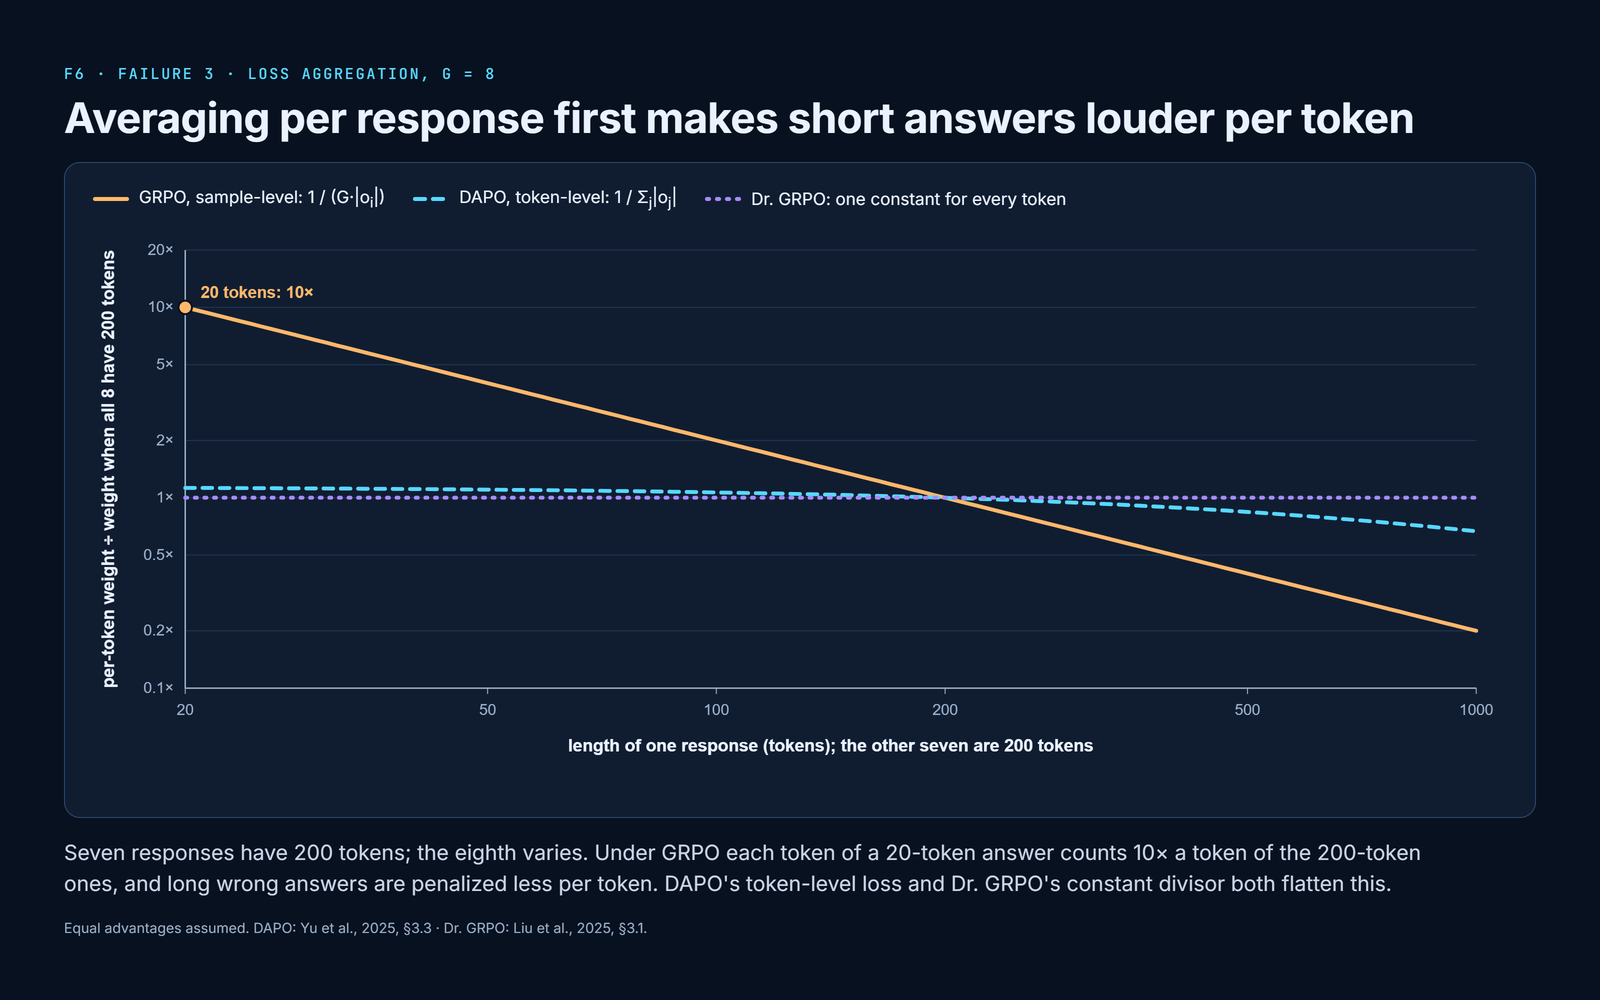

### Predict

Take a group of $G=4$ responses with lengths $[20, 40, 60, 300]$, all sharing the same nonzero advantage. Before running the next cell, guess:

1. Under sample-level (GRPO) weighting, does the 300-token response get the same *total* share of the gradient as the 20-token response?
2. Under token-level (DAPO) weighting, do individual tokens in the 300-token response get a *different* per-token weight than tokens in the 20-token response?
3. Which response ends up commanding the largest *total* share of the group's gradient under each scheme?

In [12]:
# Per-token weight and total share of each response under sample-level (GRPO) and token-level (DAPO) loss.
import numpy as np

G = 4
lengths = np.array([20, 40, 60, 300])
total_tokens = lengths.sum()

per_token_sample = 1.0 / (G * lengths)
per_token_token = np.full(G, 1.0 / total_tokens)

total_share_sample = np.full(G, 1.0 / G)
total_share_token = lengths / total_tokens

print(f"{'length':>7s} {'per-tok (sample)':>18s} {'per-tok (token)':>17s} "
      f"{'total share (sample)':>22s} {'total share (token)':>21s}")
for L, pts, ptt, tss, tst in zip(lengths, per_token_sample, per_token_token,
                                  total_share_sample, total_share_token):
    print(f"{L:7d} {pts:18.5f} {ptt:17.5f} {tss:22.1%} {tst:21.1%}")


 length   per-tok (sample)   per-tok (token)   total share (sample)   total share (token)
     20            0.01250           0.00238                  25.0%                  4.8%
     40            0.00625           0.00238                  25.0%                  9.5%
     60            0.00417           0.00238                  25.0%                 14.3%
    300            0.00083           0.00238                  25.0%                 71.4%


Sample-level hands every response an equal 25% share of the gradient no matter its length, so the 300-token response's total contribution is identical to the 20-token response's, meaning each of its individual tokens gets diluted 15x more (0.00083 versus 0.0125). Token-level hands every *token* the same weight (0.00238, identical all the way down that column), but because the 300-token response owns more tokens, it ends up commanding 71% of the group's total gradient, far more than its 20-token groupmate's mere 5%.

Neither number is "more correct" in the abstract; they encode two different notions of fairness: fairness across *responses* versus fairness across *tokens*. The real question is which one matches what you actually want a long chain of thought model to learn.

### Inspect: how the weighting shifts as one response gets longer

Fix three responses at lengths $[20, 40, 60]$ and let a fourth response's length $L$ grow from 10 up to 1000. Watch what happens to (a) that response's own per-token weight and (b) a token in one of the *other*, fixed-length responses, under both schemes.

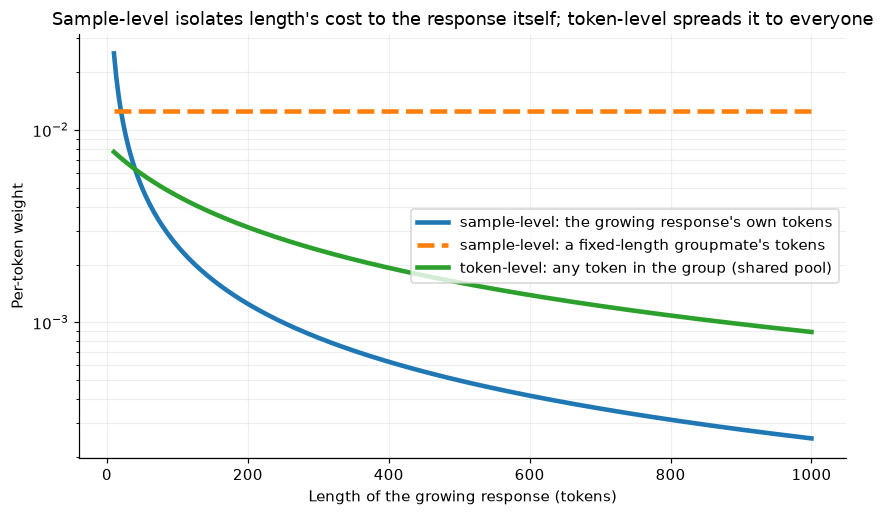

In [13]:
# Grow one response's length L and track per-token weights under both schemes (log scale).
fixed_lengths = np.array([20, 40, 60])
L_range = np.linspace(10, 1000, 300)
G_total = len(fixed_lengths) + 1

growing_per_token_sample = 1.0 / (G_total * L_range)
fixed_per_token_sample = np.full_like(L_range, 1.0 / (G_total * fixed_lengths[0]))

shared_pool = fixed_lengths.sum() + L_range
per_token_token = 1.0 / shared_pool  # identical for the growing response and every fixed one

plots.length_weights(L_range, growing_per_token_sample, fixed_per_token_sample, per_token_token)

Two patterns:

- **Sample-level** (solid blue) decays as $1/L$, but only for the response that's actually growing. The dashed orange line, a token in one of the *other*, fixed-length responses, stays constant. Under sample-level averaging, one response's length affects only its own tokens.
- **Token-level** (green) decays too, but slower, and it's a *single curve*: the growing response's own tokens and its groupmates' tokens get diluted by exactly the same amount, because they're all drawing from one shared pool. Under token-level averaging, one response getting longer slightly reduces every token's weight.

### Optimize: does the weighting change how fast a bad pattern gets suppressed?

Suppose one token, for example a repeated filler token `"um"`, shows up at every position of a long, wrong response, and nowhere else. Both loss variants apply the exact same negative advantage to every one of its occurrences; the only difference is the per-token weight computed above. We reuse the single-action logistic model from Section 1: freeze the old probability, apply repeated gradient steps scaled by the appropriate weight, and watch how fast the token's probability actually falls.

In [14]:
# Race: how fast is one repeated filler token suppressed when its gradient is scaled by the
# sample-level weight (long or short response) or by the token-level weight?
def optimize_negative_token(p_old, weight, learning_rate=2.0, epochs=800):
    """Suppress one token's probability under a fixed per-token gradient weight.

    Mirrors Section 1's optimize_positive_token, but for A = -1 and an explicit
    `weight` standing in for w^sample or w^token computed above. No clipping is
    modeled here -- this isolates the weighting effect alone.
    """
    z = logit(p_old)
    history = []
    for epoch in range(epochs):
        p = sigmoid(z)
        gradient = -weight * p * (1 - p)   # d/dz [weight * A * log p], with A = -1
        history.append({"epoch": epoch, "probability": p})
        z += learning_rate * gradient
    return history

In [15]:
p_old = 0.30
G_demo, total_tokens_demo = 4, 420   # same group as the [20, 40, 60, 300] example
long_len, short_len = 300, 20

w_sample_long = 1.0 / (G_demo * long_len)
w_sample_short = 1.0 / (G_demo * short_len)
w_token = 1.0 / total_tokens_demo

history_sample_long = optimize_negative_token(p_old, w_sample_long)
history_sample_short = optimize_negative_token(p_old, w_sample_short)
history_token_long = optimize_negative_token(p_old, w_token)

print(f"Starting probability: {p_old:.3f}\n")
print(f"Sample-level, token buried in the 300-token response: {history_sample_long[-1]['probability']:.3f}")
print(f"Sample-level, token in the 20-token response:         {history_sample_short[-1]['probability']:.3f}")
print(f"Token-level,  token buried in the 300-token response: {history_token_long[-1]['probability']:.3f}")

Starting probability: 0.300

Sample-level, token buried in the 300-token response: 0.248
Sample-level, token in the 20-token response:         0.053
Token-level,  token buried in the 300-token response: 0.179


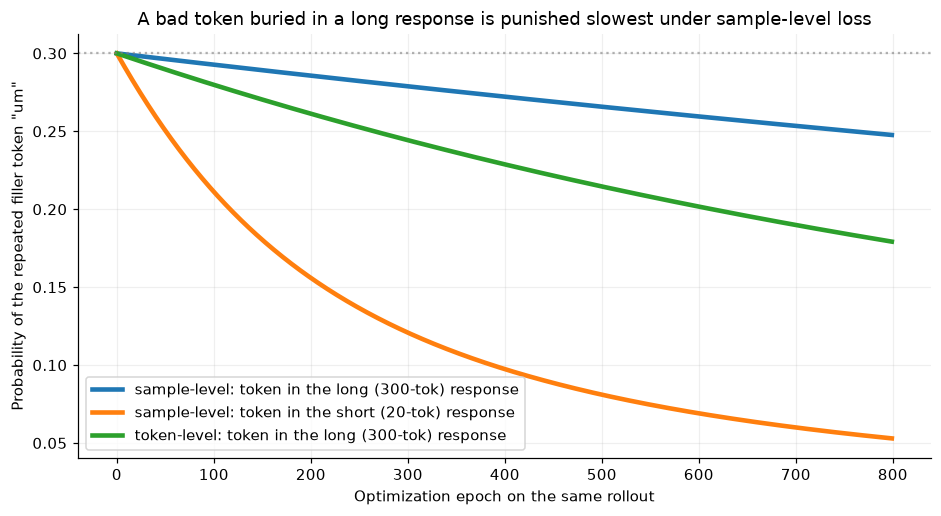

In [16]:
# Plot the three suppression curves from the previous cell.
plots.suppression_race({
    "sample-level: token in the long (300-tok) response": history_sample_long,
    "sample-level: token in the short (20-tok) response": history_sample_short,
    "token-level: token in the long (300-tok) response": history_token_long,
}, p_old)

### Explain

> Sample-level loss hands every response an equal $1/G$ share of the gradient, so an individual token's weight shrinks as $1/|o_i|$ purely because of the response it happens to sit in, with zero regard for what that token actually is. Token-level loss hands every token an equal share of a shared pool instead, so a response's *total* influence grows with its length, while any single token still has to compete for its share against however many other tokens are in the group.

This explains both halves of the paper's complaint about sample-level loss:

- **Good long reasoning goes under-taught.** A well-reasoned 300-token chain earns the same total credit as a lucky 20-token guess, so per token, the long chain's actually useful steps get reinforced far more weakly than the short one's.
- **Bad long patterns go under-punished.** A repeated filler token buried in a long wrong response gets diluted the exact same way, and it survives sample-level updates far longer than the identical token would in a short response (0.248 versus 0.053 after 800 steps above, at equal advantage and equal starting probability).

The paper reports that left uncorrected, this bias let response length and unpunished repetitive patterns grow together during training. Fixing it is the smallest jump in the ablation table, 41 to 42 on AIME 2024, one point, but the paper credits it with meaningfully healthier training dynamics (stability, controlled length growth) well beyond just raw accuracy.

Token-level loss is **not** a length bonus and does **not** directly reward verbosity: the advantage $\hat A_{i,t}$ for any given token stays exactly the same. It changes *whose* tokens get more say in the gradient, without touching what the advantage says about any of them.


### Optional exploration (no reference solution)

Extend the two weight comparison to a *full* group with random lengths and mixed correctness, rather than the fixed four response example above.

1. Write `group_weights(lengths, scheme)` returning the per-token weight array for `scheme in {"sample", "token"}`, generalizing the formulas above to an arbitrary $G$.
2. Sample $G=16$ response lengths from a skewed distribution (say `rng.gamma(2, scale=80)`, rounded to integers of at least 1) and mark each response correct or incorrect with `rng.binomial(1, p)`. Compute each response's *total* share of the group's gradient under both schemes, and plot it against response length.
3. Think through: if you optimize purely for the training objective's gradient contribution, does token-level loss give a policy any incentive to prefer emitting longer *correct* responses over shorter ones, all else equal? Is that different from the reward function itself preferring length?
4. Both schemes still use the *same* per-token advantage $\hat A_{i,t}$; neither one adds a value network or changes the reward. Which of the two adverse effects named above (under-teaching long good reasoning, under-punishing long bad patterns) does token-level loss address more directly, and which does it only partially fix?

In [17]:
def group_weights(lengths, scheme):
    """Per-token weight array, one entry per response, for scheme in {"sample", "token"}."""
    lengths = np.asarray(lengths, dtype=float)
    G = len(lengths)
    # TODO: return per-token weight for each response under `scheme`
    # sample-level: 1 / (G * lengths[i]) for response i's own tokens
    # token-level:  1 / lengths.sum(), the same for every response
    return np.zeros(G)

# Once implemented:
# rng = np.random.default_rng(2)
# lengths = np.maximum(1, rng.gamma(2, scale=80, size=16)).astype(int)
# correct = rng.binomial(1, 0.5, size=16)
# total_share_sample = group_weights(lengths, "sample") * lengths
# total_share_token = group_weights(lengths, "token") * lengths


---

## 4. Overlong Reward Shaping: Give Length Its Own Gradient *(about 10 min)*

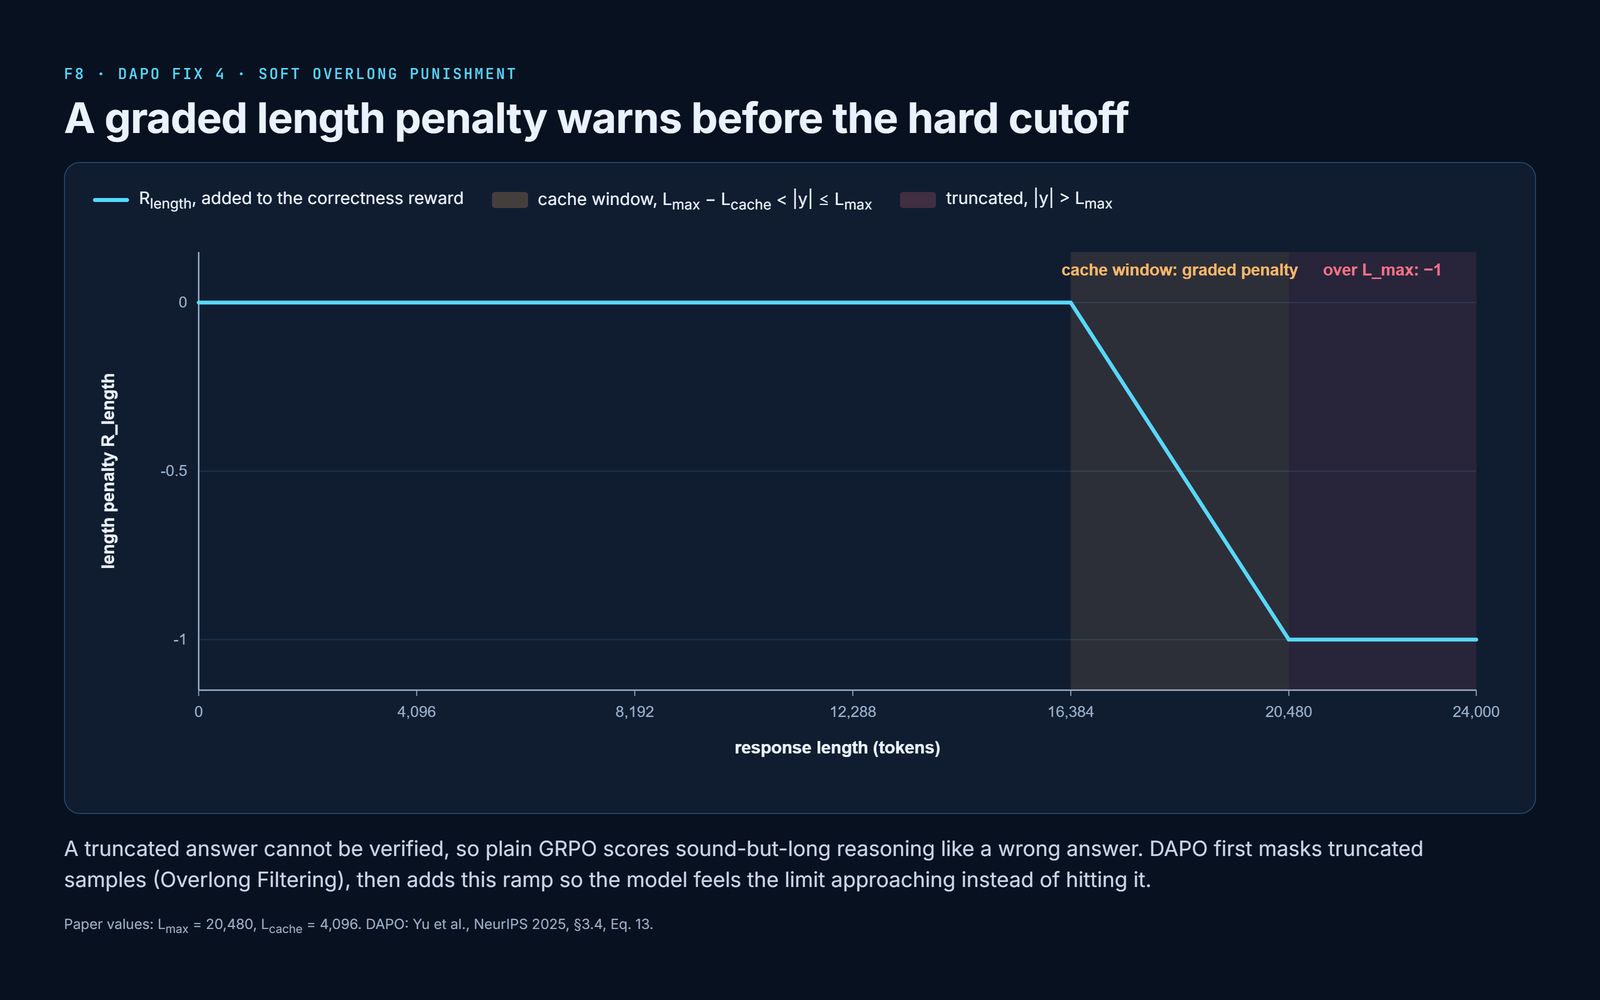

**What you'll observe:** a graded penalty in the cache window catches length drift before responses hit the truncation limit.

**What changes.** The first three fixes all left the reward $R_i$ alone and changed how the objective used it. This one changes $R_i$ itself. Recall the rule-based reward (Eq. 7): $R_i=+1$ if the final answer matches the ground truth, $-1$ otherwise. DAPO adds a second, length-aware term to it (Eq. 13):

$$R_i \;=\; R_{\mathrm{rule}}(o_i, a) \;+\; R_{\mathrm{length}}(|o_i|), \qquad
R_{\mathrm{length}}(y)=\begin{cases}
0, & |y|\le L_{\max}-L_{\mathrm{cache}}\\[4pt]
\dfrac{(L_{\max}-L_{\mathrm{cache}})-|y|}{L_{\mathrm{cache}}}, & L_{\max}-L_{\mathrm{cache}}<|y|\le L_{\max}\\[6pt]
-1, & L_{\max}<|y|
\end{cases}$$

$L_{\max}$ is the hard generation budget: the sampler stops there. $L_{\mathrm{cache}}$ carves out a "soft punishment cache" just below that ceiling: inside it, the penalty ramps down linearly from $0$ to $-1$; below it, $R_{\mathrm{length}}=0$ and nothing changes at all. Everything else (the objective's shape, the clipping, the averaging) stays as it is in whichever of Sections 1 through 3 you're combining this with.

### Question to consider

A response is reasoning soundly toward the correct answer, but the generation budget runs out before it emits a final answer, so it gets truncated mid-sentence. Under the rule-based reward alone, what does it receive, and does that have anything to do with how sound its reasoning actually was up to the cutoff?

`is_equivalent` has nothing to compare against: there is no final answer to check. A rule-based verifier can only treat it as wrong, $R_{\mathrm{rule}}=-1$, **regardless of the quality of the reasoning before the cutoff.** The group-normalized advantage then spreads that $-1$ across every token of the response, including whatever excellent early reasoning it contained, purely because the response ran out of room. Call this **truncation noise**: the sign of the reward gets decided by a token budget, not by content.

The paper's ablation names this diagnosis directly with *Overlong Filtering*, simply **masking the loss** on truncated samples instead of scoring them $-1$. That alone produces the largest single early jump in the table, $30\to36$ on AIME 2024, confirming truncation noise really is a sizable problem. But masking a sample is the same move as Dynamic Sampling's unanimous groups from Section 2: the rollout gets generated and then thrown away, contributing nothing at all. *Soft Overlong Punishment* (Eq. 13, above) recovers a usable signal instead of discarding it, and as a side effect, it discourages every response, not just truncated ones, from drifting toward the budget in the first place.

### Predict

Take the paper's toy scale from the reference implementation: $L_{\max}=100$, $L_{\mathrm{cache}}=20$ (so the soft window is $(80, 100]$). Three responses in a group:

| Response | Length $|o_i|$ | Finished? | Correct? |
|---|---:|---|---|
| A | 50 | yes | yes |
| B | 92 | yes (just rambled) | yes |
| C | 100 | no, hit the budget | unknown |

Before running the next cell, guess each response's $R_{\mathrm{rule}}$, $R_{\mathrm{length}}$, and total $R_i$. In particular: does B, which is fully correct, still lose anything? Does C's total reward drop *below* $-1$?

In [18]:
# Rule reward + DAPO's length penalty (Eq. 13) for the three example responses A, B and C.
L_MAX, L_CACHE = 100, 20   # same toy scale as the reference implementation's own doctest

def rule_reward(is_correct):
    return 1.0 if is_correct else -1.0

def length_penalty(length, L_max=L_MAX, L_cache=L_CACHE):
    """Eq. 13: R_length(y). 0 below the cache window, ramps to -1 at L_max, -1 beyond it."""
    if length <= L_max - L_cache:
        return 0.0
    elif length <= L_max:
        return ((L_max - L_cache) - length) / L_cache
    else:
        return -1.0

responses = [
    {"name": "A", "length": 50, "finished": True, "correct": True},
    {"name": "B", "length": 92, "finished": True, "correct": True},
    {"name": "C", "length": 100, "finished": False, "correct": None},
]

print(f"{'resp':>4s} {'length':>7s} {'R_rule':>7s} {'R_length':>9s} {'total R':>8s}")
for r in responses:
    # A response that never finished has no answer to check -- is_equivalent is always False.
    r_rule = rule_reward(r["correct"] if r["finished"] else False)
    r_len = length_penalty(r["length"])
    total = r_rule + r_len
    print(f"{r['name']:>4s} {r['length']:7d} {r_rule:7.2f} {r_len:9.2f} {total:8.2f}")


resp  length  R_rule  R_length  total R
   A      50    1.00      0.00     1.00
   B      92    1.00     -0.60     0.40
   C     100   -1.00     -1.00    -2.00


Yes to both. B is fully correct but still surrenders $0.6$ of its reward for rambling into the cache window, so length now costs a genuinely successful response something, not just a failed one. And C's total is $-2$: it stacks the $-1$ it already earned from having no verifiable answer on top of a second $-1$ for hitting the ceiling. This is by construction: at $|y|=L_{\max}$ the ramp evaluates to exactly $-1$ by construction, so *every* truncated response pays the full length penalty on top of whatever `R_rule` already gave it.

### Inspect: the reward landscape as a function of length

Fix correctness and vary length across the whole axis, for both the *old* scheme (rule-based reward alone, the implicit baseline before this fix) and the *new* one (rule-based plus $R_{\mathrm{length}}$).

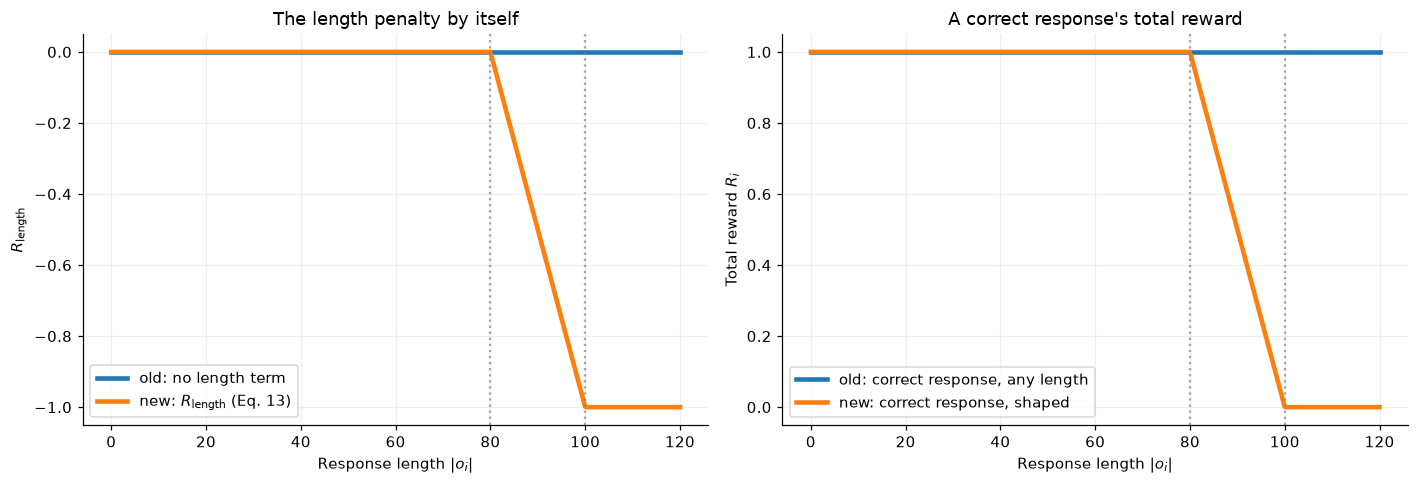

In [19]:
# The length penalty alone (left) and a correct response's total reward (right), old vs new scheme.
lengths = np.linspace(0, 120, 600)
r_length_curve = np.array([length_penalty(L) for L in lengths])
plots.length_penalty_schemes(lengths, r_length_curve, L_MAX, L_CACHE)

(The curve is drawn past $L_{\max}=100$ only to show the formula's third case; in practice the sampler stops generation at $L_{\max}$, so no real response is ever longer than that.)

Left panel: the old scheme supplies no information about length: a flat line at $0$. The new one is flat at $0$ too, but only up to the cache boundary; past it, it slopes smoothly down to $-1$. Right panel: a correct response's reward under the old scheme is a flat $+1$ at any length; length is invisible to the objective. Under the new scheme the same response's reward bends downward well before it would ever actually be truncated, so the model has gradient to act on *before* hitting the wall, not only after.

### Optimize: does the model see the wall coming before it hits it?

The paper reports that naive GRPO's average response length drifts upward over training. We simulate that drift as a sweep over training steps and, at each step, ask what fraction of the batch's responses fall into three zones: safely below the cache window, inside it, or truncated at $L_{\max}$. The old scheme only ever "sees" that last zone; Soft Overlong Punishment sees the middle one too.

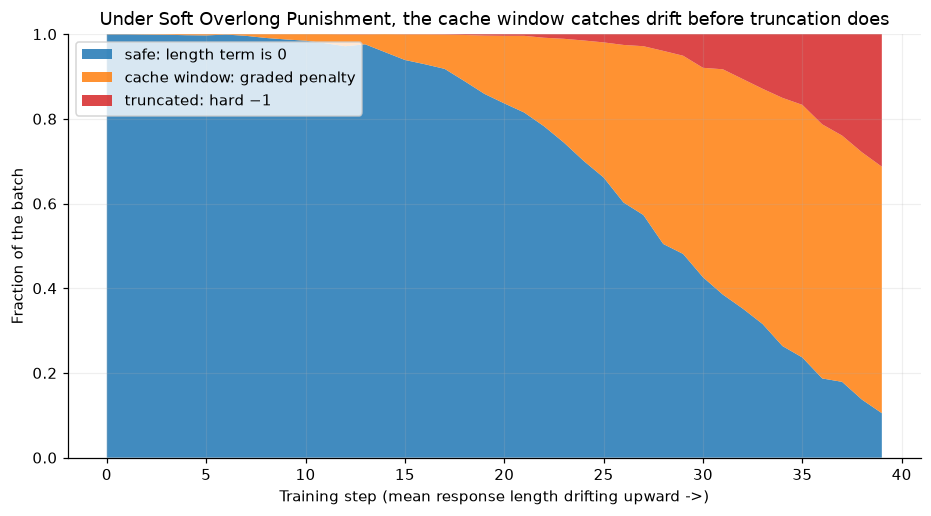

 step  mean len    safe  in cache  truncated
    0      40.0  100.0%      0.1%       0.0%
   10      54.0   98.5%      1.6%       0.0%
   20      68.0   83.7%     16.0%       0.4%
   30      82.0   42.6%     49.5%       8.0%
   39      94.6   10.5%     58.2%      31.3%


In [20]:
# Simulate upward length drift and measure the share of responses in the safe zone, the cache window,
# and at the truncation limit.
rng = np.random.default_rng(3)
BATCH = 2000

def zone_fractions(mean_length, sigma=12, n=BATCH):
    """Sample response lengths and split them into safe / cache-window / truncated."""
    raw = rng.normal(mean_length, sigma, n)
    lengths = np.clip(raw, 1, L_MAX)          # the sampler itself enforces the L_max wall
    safe = np.mean(lengths <= L_MAX - L_CACHE)
    in_cache = np.mean((lengths > L_MAX - L_CACHE) & (lengths < L_MAX))
    truncated = np.mean(lengths >= L_MAX)
    return safe, in_cache, truncated

steps = np.arange(0, 40)
mean_lengths = 40 + 1.4 * steps   # naive GRPO's average response length drifting upward

safe_frac, cache_frac, truncated_frac = np.array(
    [zone_fractions(m) for m in mean_lengths]
).T

plots.length_zones(steps, safe_frac, cache_frac, truncated_frac)

print(f"{'step':>5s} {'mean len':>9s} {'safe':>7s} {'in cache':>9s} {'truncated':>10s}")
for s in (0, 10, 20, 30, 39):
    print(f"{s:5d} {mean_lengths[s]:9.1f} {safe_frac[s]:7.1%} {cache_frac[s]:9.1%} {truncated_frac[s]:10.1%}")

### Explain

> By step 30 above, mean length has drifted to 82: about half the batch (49.5%) is already sitting inside the cache window and receiving a graded penalty, while only 8.0% has actually hit the wall. Under the old scheme, that 50% is invisible: the reward says nothing until a response gets truncated outright. Soft Overlong Punishment turns "half the batch is drifting toward the cliff" into a training signal *before* it ever becomes "half the batch fell off it."

> The mechanism is simple: $R_{\mathrm{length}}$ is just a deterministic function of length, added to the same rule-based reward used everywhere else in this notebook. It does not touch the objective's shape (Sections 1 and 3) or which groups are kept (Section 2); it only makes sure the reward those mechanisms consume actually contains information about length before the length limit forces the issue.

In the ablation, the two length-related rows show two steps: *Overlong Filtering* (masking truncated samples' loss) is the diagnostic that first proved truncation noise costs real accuracy, $30\to36$, the largest jump among the early rows of the table (Dynamic Sampling's $42\to50$ is the largest overall). *Soft Overlong Punishment* replaces masking with shaping once Clip-Higher is already in place, $38\to41$, recovering a training signal from exactly the samples Overlong Filtering had been throwing away.

What this fix is **not**: it is not a substitute for Dynamic Sampling (Section 2), since a group can still end up unanimous even with length-shaped rewards, and it doesn't by itself guarantee shorter responses on average; it only guarantees that length has *some* gradient before the hard wall, rather than none.


### Optional exploration (no reference solution)

1. Reimplement `length_penalty` to also support $L_{\mathrm{cache}}=0$, and check that it degenerates to a pure hard cutoff (0 everywhere except exactly $-1$ at and beyond $L_{\max}$). Why might a practitioner ever actually want $L_{\mathrm{cache}}=0$?
2. Extend `zone_fractions` to report, at each step, the *average total reward* of correct responses only (mixing `rule_reward(True)` with `length_penalty`). Plot it alongside the stacked zone chart. Does a correct response's expected reward decay smoothly as the mean length drifts, or does it stay pinned near $+1$ right up until the wall?
3. The paper sets $L_{\max}=20{,}480$ and $L_{\mathrm{cache}}=4{,}096$, so the cache is exactly 20% of the budget. Sweep the cache fraction (holding $L_{\max}$ fixed) from 5% to 50% in the training run simulation above. What happens to how early the model gets a length signal, versus how much it costs correct but merely verbose responses?
4. Across all four sections: Clip-Higher changes the clip bounds, Dynamic Sampling changes which groups get kept, Token-Level Loss changes how tokens get weighted, and Overlong Reward Shaping changes the reward itself. If you could only keep two of the four under a fixed compute budget, which two would you keep, and what specific failure mode would you be willing to live with?

In [21]:
def length_penalty_general(length, L_max, L_cache):
    """Generalized Eq. 13 -- TODO: handle L_cache == 0 as a pure hard cutoff."""
    # TODO: mirror length_penalty above, but guard the division by L_cache.
    return 0.0

# Once implemented:
# assert length_penalty_general(50, L_max=100, L_cache=0) == 0.0
# assert length_penalty_general(100, L_max=100, L_cache=0) == -1.0
# assert length_penalty_general(101, L_max=100, L_cache=0) == -1.0


---

## Reference

![Bar chart of DAPO's cumulative ablation on AIME 2024 (avg@32, Qwen2.5-32B base): naive GRPO 30, plus overlong filtering 36, plus Clip-Higher 38, plus soft overlong punishment 41, plus token-level loss 42, plus Dynamic Sampling 50, against DeepSeek-R1-Zero-Qwen-32B at 47.](attachment:F14a_dapo_ablation.png)

Yu et al. (2025), [DAPO: An Open-Source LLM Reinforcement Learning System at Scale](https://arxiv.org/abs/2503.14476). Equation and figure numbers throughout refer to this paper.

Secondary explainer: [DAPO: Enhancing GRPO For LLM Reinforcement Learning](https://aipapersacademy.com/dapo/), AI Papers Academy, a plain-language walkthrough of the same four techniques.

Companion notebook: [`disco_three_fixes.ipynb`](disco_three_fixes.ipynb), on Li et al. (2025), [DisCO: Reinforcing Large Reasoning Models with Discriminative Constrained Optimization](https://arxiv.org/abs/2505.12366), a different, complementary set of fixes over the same GRPO objective.

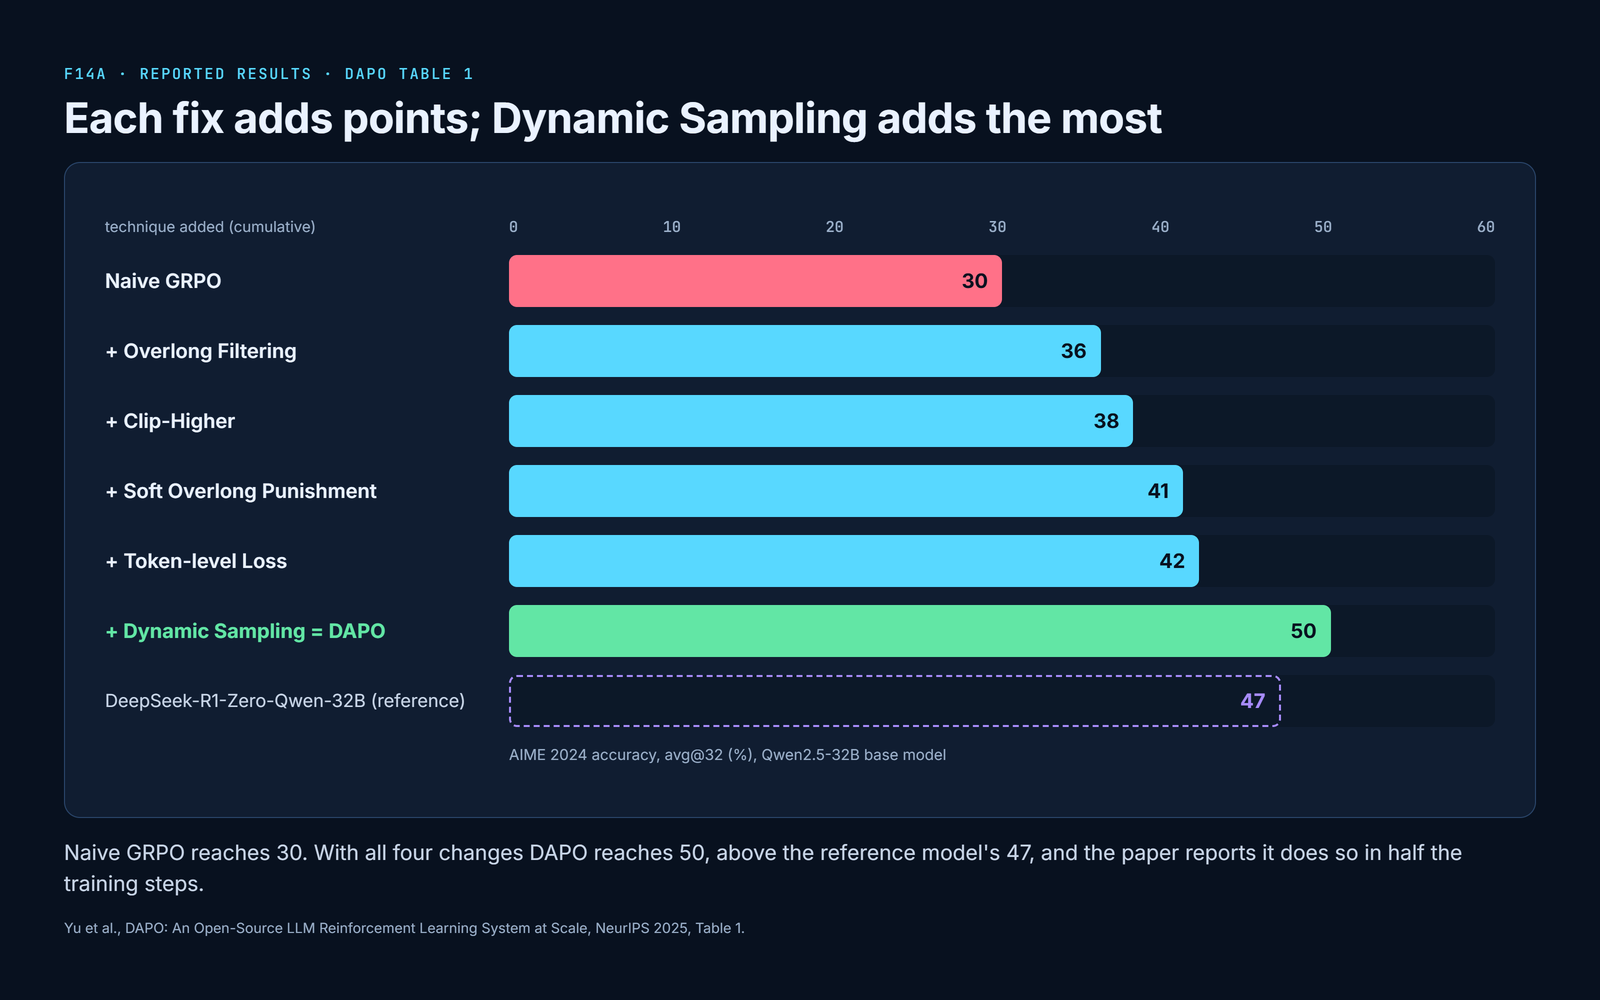